In [16]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    mutual_info_score
)

from itertools import combinations

from preprocessing import (
    load_adult,
    to_categories,
    save_predictions,
    save_model,
    add_label_noise
)

In [2]:
#loading the dataset
trainDf, testDf = load_adult()
print(trainDf.shape)
print(testDf.shape)
trainDf.head()

(32561, 15)
(16281, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [3]:
#seperating features and labels
xTrain = trainDf.drop(columns=["income"])
yTrain = trainDf["income"]

xTest = testDf.drop(columns=["income"])
yTest = testDf["income"]

In [4]:
#preprocessing features
xTrainCat, xTestCat = to_categories(trainDf, testDf)

print(xTrainCat.shape)
print(xTestCat.shape)
xTrainCat.head()

(32561, 14)
(16281, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,3,6,0,9,8,4,0,1,4,1,6,0,3,38
1,4,5,0,9,8,2,3,0,4,1,0,0,1,38
2,2,3,1,11,5,0,5,1,4,1,0,0,3,38
3,4,3,1,1,4,2,5,0,2,1,0,0,3,38
4,1,3,2,9,8,2,9,5,2,0,0,0,3,4


In [5]:
#checking min & max
for col in xTrainCat.columns:
    print(col, xTrainCat[col].min(), xTestCat[col].min(),
          xTrainCat[col].max(), xTestCat[col].max())

age 0 0 9 9
workclass 0 0 8 8
fnlwgt 0 0 9 9
education 0 0 15 15
education-num 0 0 9 9
marital-status 0 0 6 6
occupation 0 0 14 14
relationship 0 0 5 5
race 0 0 4 4
sex 0 0 1 1
capital-gain 0 0 9 9
capital-loss 0 0 9 9
hours-per-week 0 0 9 9
native-country 0 0 41 41


In [6]:
#training initial Naive Bayes model
nbModel = CategoricalNB()
nbModel.fit(xTrainCat, yTrain)

CategoricalNB()

In [7]:
#evaluating initial model
yPred = nbModel.predict(xTestCat)

initialAccuracy = accuracy_score(yTest, yPred)

print("Naive Bayes Accuracy:", initialAccuracy)
print(classification_report(yTest, yPred))
print(confusion_matrix(yTest, yPred))

Naive Bayes Accuracy: 0.8251335913027456
              precision    recall  f1-score   support

           0       0.92      0.84      0.88     12435
           1       0.60      0.77      0.68      3846

    accuracy                           0.83     16281
   macro avg       0.76      0.81      0.78     16281
weighted avg       0.85      0.83      0.83     16281

[[10463  1972]
 [  875  2971]]


In [8]:
#setting up grid search and cross validation
paramGrid = {
    "alpha": [0.1, 0.5, 1.0, 2.0, 5.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [9]:
#running grid search
grid = GridSearchCV(
    CategoricalNB(),
    paramGrid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True
)

grid.fit(xTrainCat, yTrain)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=CategoricalNB(),
             param_grid={'alpha': [0.1, 0.5, 1.0, 2.0, 5.0]},
             return_train_score=True, scoring='accuracy')

In [10]:
#grid search results
trainAcc = grid.cv_results_["mean_train_score"][grid.best_index_]
valAcc = grid.best_score_

print(f"Best alpha: {grid.best_params_['alpha']}")
print(f"Training accuracy: {trainAcc:.1%}")
print(f"Validation accuracy: {valAcc:.1%}")

Best alpha: 5.0
Training accuracy: 82.4%
Validation accuracy: 82.4%


In [11]:
#evaluating with grid and cross validation
yPredTuned = grid.predict(xTestCat)
testAcc = accuracy_score(yTest, yPredTuned)

print(f"Tuned Naive Bayes Test Accuracy: {testAcc:.1%}")

Tuned Naive Bayes Test Accuracy: 82.6%


In [12]:
#model result summary
results = pd.DataFrame({
    "Metric": [
        "Initial Test Accuracy",
        "Best Alpha",
        "Training Accuracy",
        "Cross-Validation Accuracy",
        "Tuned Test Accuracy"
    ],
    "Result": [
        f"{initialAccuracy:.2%}",
        grid.best_params_["alpha"],
        f"{trainAcc:.2%}",
        f"{valAcc:.2%}",
        f"{testAcc:.2%}"
    ]
})

display(results)

,Metric,Result
0,Initial Test Accuracy,82.51%
1,Best Alpha,5.0
2,Training Accuracy,82.43%
3,Cross-Validation Accuracy,82.39%
4,Tuned Test Accuracy,82.60%


In [13]:
#prepare noisy labels for all experiments
noiseLevels = [0, 0.1, 0.2, 0.3, 0.4]
seeds = [0, 1, 2, 3, 4]

noisyLabels = {}

for seed in seeds:
    for noiseLevel in noiseLevels:
        noisyTrain = add_label_noise(
            trainDf, noiseLevel, seed
        )

        noisyLabels[(seed, noiseLevel)] = noisyTrain["income"]

print("Number of noisy label sets:", len(noisyLabels))

Number of noisy label sets: 25


In [ ]:
#repeat noise experiments with different random seeds
repeatResults = []
runs = []

for seed in seeds:
    for noiseLevel in noiseLevels:

        #reuse previously generated noisy labels
        yTrainNoisy = noisyLabels[(seed, noiseLevel)]

        #retune hyperparameters using noisy training data
        noiseGrid = GridSearchCV(
            CategoricalNB(),
            paramGrid,
            cv=cv,
            scoring="accuracy"
        )

        noiseGrid.fit(xTrainCat, yTrainNoisy)
        model = noiseGrid.best_estimator_

        #evaluate on clean test data
        yPred = model.predict(xTestCat)
        errorRate = 1 - accuracy_score(yTest, yPred)

        runs.append((
            noiseLevel, seed,
            model.predict_proba(xTestCat)[:, 1]
        ))

        if seed == 0:
            save_model("naiveBayes", noiseLevel, model)

        repeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Best Alpha": noiseGrid.best_params_["alpha"],
            "Error Rate": errorRate,
            "Precision >50K": precision_score(
                yTest, yPred, zero_division=0
            ),
            "Recall >50K": recall_score(
                yTest, yPred, zero_division=0
            )
        })

repeatDf = pd.DataFrame(repeatResults)
save_predictions("naiveBayes", runs)

#average error across the five runs
summaryDf = repeatDf.groupby("Noise Level")["Error Rate"].agg(
    ["mean", "std"]
)

display(summaryDf)

,mean,std
Noise Level,,
0.0,0.174007,0.000000
0.1,0.189423,0.001028
0.2,0.198550,0.001044
0.3,0.205381,0.001324
0.4,0.212886,0.003642


In [15]:
display(repeatDf)

,Seed,Noise Level,Best Alpha,Error Rate
0,0,0.0,5.0,0.174007
1,0,0.1,5.0,0.188256
2,0,0.2,5.0,0.198575
3,0,0.3,5.0,0.205638
4,0,0.4,5.0,0.209139
5,1,0.0,5.0,0.174007
6,1,0.1,1.0,0.188379
7,1,0.2,0.1,0.197838
8,1,0.3,5.0,0.205823
9,1,0.4,2.0,0.216694


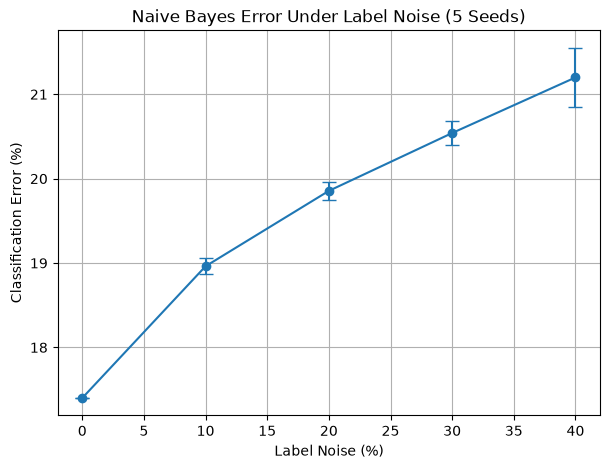

In [15]:
#plot average classification error with standard deviation
plt.figure(figsize=(7, 5))

plt.errorbar(
    summaryDf.index * 100,
    summaryDf["mean"] * 100,
    yerr=summaryDf["std"] * 100,
    marker="o",
    capsize=5
)

plt.xlabel("Label Noise (%)")
plt.ylabel("Classification Error (%)")
plt.title("Naive Bayes Error Under Label Noise (5 Seeds)")
plt.grid(True)
plt.show()

In [17]:
#generating all unique feature pairs
featurePairs = list(combinations(xTrainCat.columns, 2))

print("Number of feature pairs:", len(featurePairs))
print(featurePairs[:5])

Number of feature pairs: 91
[('age', 'workclass'), ('age', 'fnlwgt'), ('age', 'education'), ('age', 'education-num'), ('age', 'marital-status')]


In [ ]:
#calculate information loss for any feature pair
def calculateInfoLoss(y, featurePair):
    labels = pd.Series(np.asarray(y))

    features = xTrainCat[list(featurePair)]

    jointFeature = features[featurePair[0]].astype(str) + "_" + features[featurePair[1]].astype(str)

    trueMI = mutual_info_score(jointFeature, labels)

    classProbs = labels.value_counts(normalize=True).sort_index()

    feature1Probs = pd.crosstab(
        labels,
        features[featurePair[0]].reset_index(drop=True),
        normalize="index"
    )

    feature2Probs = pd.crosstab(
        labels,
        features[featurePair[1]].reset_index(drop=True),
        normalize="index"
    )

    pC = classProbs.to_numpy()
    pF1 = feature1Probs.to_numpy()
    pF2 = feature2Probs.to_numpy()

    pJoint = pC[:, None, None] * pF1[:, :, None] * pF2[:, None, :]
    pFeatures = pJoint.sum(axis=0)

    denominator = pC[:, None, None] * pFeatures[None, :, :]
    mask = pJoint > 0

    nbMI = np.sum(
        pJoint[mask] * np.log(pJoint[mask] / denominator[mask])
    )

    return trueMI - nbMI

In [19]:
#test information loss on different feature pairs
for featurePair in featurePairs[:5]:
    infoLoss = calculateInfoLoss(yTrain, featurePair)
    print(featurePair, infoLoss)

('age', 'workclass') -0.004228329598388217
('age', 'fnlwgt') 0.0006436048467726163
('age', 'education') -0.0035462549246970537
('age', 'education-num') -0.0028299729223317527
('age', 'marital-status') -0.02855641403397835


In [ ]:
#class-conditional dependence between two features: I(X1; X2 | income)
def calculateDependence(x1, x2, y):
    x1, x2, y = np.asarray(x1), np.asarray(x2), np.asarray(y)
    return sum((y == c).mean() * mutual_info_score(x1[y == c], x2[y == c]) for c in (0, 1))
#each person's combination of the two values, e.g. "3_1", for every pair
pairCombos = {}
for featurePair in featurePairs:
    pairCombos[featurePair] = (
        xTrainCat[featurePair[0]].astype(str) + "_" + xTrainCat[featurePair[1]].astype(str),
        xTestCat[featurePair[0]].astype(str) + "_" + xTestCat[featurePair[1]].astype(str),
    )

In [ ]:
#evaluate all feature pairs under different noise levels
from pathlib import Path

Path("results").mkdir(exist_ok=True)

pairResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:

        #reuse noisy labels
        yTrainNoisy = noisyLabels[(seed, noiseLevel)]

        for featurePair in featurePairs:

            #select two features
            xTrainPair = xTrainCat[list(featurePair)]
            xTestPair = xTestCat[list(featurePair)]

            #retune Naive Bayes
            pairGrid = GridSearchCV(
                CategoricalNB(),
                paramGrid,
                cv=cv,
                scoring="accuracy"
            )

            pairGrid.fit(xTrainPair, yTrainNoisy)

            #evaluate on clean test data
            yPred = pairGrid.predict(xTestPair)
            accuracy = accuracy_score(yTest, yPred)

            #calculate information loss
            infoLoss = calculateInfoLoss(
                yTrainNoisy, featurePair
            )
            #memorize model: majority income for each combination (Rish's Bayes-optimal classifier)
            trainCombo, testCombo = pairCombos[featurePair]
            majority = (pd.Series(np.asarray(yTrainNoisy)).groupby(trainCombo.values).mean() > 0.5).astype(int)
            memoError = (testCombo.map(majority).fillna(0) != yTest).mean()

            dependence = calculateDependence(
                xTrainPair[featurePair[0]], xTrainPair[featurePair[1]], yTrainNoisy
            )

            #record experiment results
            pairResults.append({
                "Model": "naiveBayes",
                "Feature 1": featurePair[0],
                "Feature 2": featurePair[1],
                "Seed": seed,
                "Noise Level": noiseLevel,
                "Best Alpha": pairGrid.best_params_["alpha"],
                "Accuracy": accuracy,
                "Error Rate": 1 - accuracy,
                "Information Loss": infoLoss,
                "Dependence": dependence,
                "Memorize Error": memoError,
                "Extra Error": (1 - accuracy) - memoError
            })

        #save progress after each seed and noise level
        pd.DataFrame(pairResults).to_csv(
            "results/naiveBayes_scores.csv",
            index=False
        )

        print(f"Completed seed {seed}, noise {noiseLevel}")

#display final results
pairResultsDf = pd.DataFrame(pairResults)

display(pairResultsDf.head())
print("Total results:", len(pairResultsDf))

Completed seed 0, noise 0
Completed seed 0, noise 0.1


KeyboardInterrupt: 

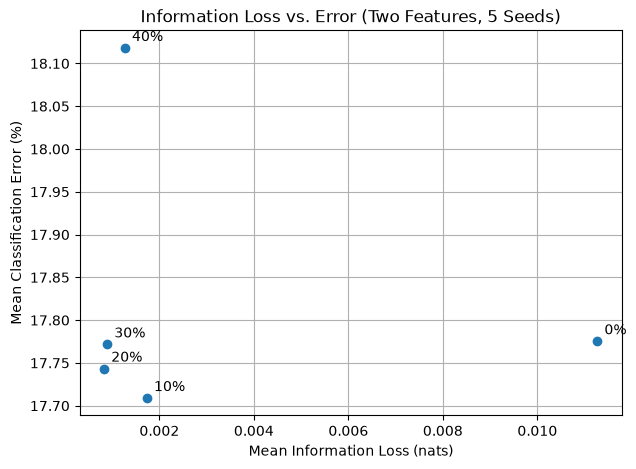

In [ ]:
#compare information loss and classification error
pairSummaryDf = pairResultsDf.groupby(
    ["Feature 1", "Feature 2", "Noise Level"],
    as_index=False
)[["Information Loss", "Error Rate"]].mean()

plt.figure(figsize=(9, 6))

for noiseLevel in noiseLevels:
    subset = pairSummaryDf[
        pairSummaryDf["Noise Level"] == noiseLevel
    ]

    plt.scatter(
        subset["Information Loss"],
        subset["Error Rate"] * 100,
        label=f"{noiseLevel * 100:.0f}% Noise",
        alpha=0.6
    )

plt.xlabel("Mean Information Loss (nats)")
plt.ylabel("Mean Classification Error (%)")
plt.title("Information Loss vs. Error (91 Feature Pairs)")
plt.legend()
plt.grid(True)
plt.show()

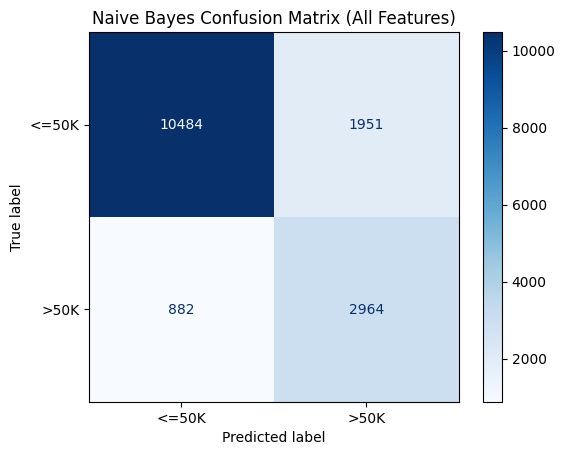

              precision    recall  f1-score   support

       <=50K       0.92      0.84      0.88     12435
        >50K       0.60      0.77      0.68      3846

    accuracy                           0.83     16281
   macro avg       0.76      0.81      0.78     16281
weighted avg       0.85      0.83      0.83     16281



In [23]:
#train full Naive Bayes model without label noise
model = CategoricalNB(alpha=grid.best_params_["alpha"])
model.fit(xTrainCat, yTrain)

#predict on clean test data
yPred = model.predict(xTestCat)

#display confusion matrix
cm = confusion_matrix(yTest, yPred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
).plot(cmap="Blues", values_format="d")

plt.title("Naive Bayes Confusion Matrix (All Features)")
plt.show()

#classification report
print(classification_report(
    yTest,
    yPred,
    target_names=["<=50K", ">50K"]
))

In [ ]:
#precision and recall under label noise (5 seeds)
metricSummaryDf = repeatDf.groupby("Noise Level")[
    ["Precision >50K", "Recall >50K"]
].agg(["mean", "std"])

display(metricSummaryDf)

Precision >50K           Recall >50K          
                      mean       std        mean       std
Noise Level                                               
0.0               0.714414  0.000000    0.412376  0.000000
0.1               0.713576  0.000403    0.418201  0.001577
0.2               0.710360  0.003804    0.420281  0.003748
0.3               0.708464  0.002181    0.420905  0.003144
0.4               0.682811  0.022122    0.437441  0.018023